# Explaining the network by occlusion, and what it misses

**Explanation notebook 2 in `notebooks/xai/`.** `notebooks/README.md` says how every notebook is laid out, and `notebooks/xai/README.md` says what every explanation notebook shares. Read `01_shap_fd001.ipynb` first: this notebook uses its words — stand-in, reference prediction, efficiency — and compares everything against its Shapley values.

## What this notebook is for

**Occlusion** is the simplest way there is to ask which sensors a prediction came from: replace one sensor's readings with a typical reading, run the network again, and see how far the prediction moves. It is **not in the paper**. It is here for two reasons. It is cheap — 15 runs of the network per window, where exact Shapley values need 16,384 — so it is the method someone in a hurry would reach for. And setting it beside the Shapley values of the same network, on the same engine, shows exactly what the Shapley average adds and when leaving it out goes wrong.

## What it does not do

- **It does not train anything.** It loads the same stored network the Shapley notebook explains.
- **It does not show that one method is better in general.** It compares the two on one network and one engine. What it shows in general is the arithmetic of section 1, which holds for any network.
- **It does not say what wears an engine**, for the same reasons the Shapley notebook gives.

## The notebook in one list

| # | Step | What goes in | What comes out |
|---|------|--------------|----------------|
| 1 | **Load** the trained network | the stored five-seed run | seed 42's network and its data, checked against the run |
| 2 | **Occlude one window by hand** | one window, the stand-in window | 15 predictions, and 14 occlusion values |
| 3 | **Find occlusion inside Equation 15** | the same window | the one term of the Shapley sum occlusion keeps, and what it leaves out |
| 4 | **Follow the same engine's life** | every window of the engine the Shapley notebook follows | both methods at every cycle, drawn on one chart |
| 5 | **Measure where they agree** | both sets of values | how far occlusion misses adding up, how its ranking compares, and what each costs |

## 1. Background

### Occlusion, defined

For one window, the **occlusion value** of a sensor is

```
occlusion(sensor) = f(every sensor real)  −  f(every sensor real except this one, which gets its stand-in)
```

where `f` is the network's prediction, in cycles. A positive value means the sensor's real readings held the prediction higher than typical readings would have. The stand-in is the one the Shapley notebook uses: the sensor's average window over the training engines (assumption A-20). Occlusion needs one run of the network on the real window and one per sensor, so 1 + 14 = 15 runs.

### The same toy example, and the first thing that goes wrong

The Shapley notebook's section 1 used `f(a, b) = 2a + 3b + 4ab`, the input `a = 1, b = 1`, and the reference `a = 0, b = 0`, where the whole change to explain was `9`. Occlusion gives:

- `a`: `f(1, 1) − f(0, 1) = 9 − 3 = 6`
- `b`: `f(1, 1) − f(1, 0) = 9 − 2 = 7`

The two add up to 13, not 9. Each input is measured with the other already present, so each is credited with the whole interaction term `4ab`, and the interaction is counted twice. The Shapley values were 4 and 5, which do add up to 9.

### The second thing that goes wrong: two sensors that say the same thing

Take a different toy function, in which the output only needs one of two inputs to be on:

```
g(a, b) = 10 × max(a, b)
```

With the input `a = 1, b = 1` and the reference `a = 0, b = 0`, the whole change is `g(1, 1) − g(0, 0) = 10`. Occlusion gives:

- `a`: `g(1, 1) − g(0, 1) = 10 − 10 = 0`
- `b`: `g(1, 1) − g(1, 0) = 10 − 10 = 0`

Both inputs look useless, although together they produced the whole output. Removing either one alone changes nothing because the other still carries the same information. The Shapley average sees it: `a` adds 10 when it arrives first and 0 when it arrives second, so its value is 5, and so is `b`'s. Correlated sensors on a jet engine carry overlapping information, so this is not an exotic case.

### Where occlusion sits inside the Shapley value

In the Shapley notebook's order table, each row records what a sensor adds when it arrives in some order. The occlusion value is exactly **what the sensor adds when it arrives last**, after every other sensor is already present: `f(everything) − f(everything but this one)`. The Shapley value averages what the sensor adds over every position it could arrive in; occlusion keeps only the last position.

That also says when the two agree. If a sensor added the same amount wherever it arrived — no interactions with any other sensor — every row of the order table would hold the same number, the average would equal the last row, and occlusion would give the Shapley value. The further apart a sensor's contributions are across positions, the further apart the two methods.

**Do not confuse** occlusion with its mirror image, switching on one sensor alone from a window made entirely of stand-ins: `f(only this sensor real) − f(no sensor real)`. That is what a sensor adds when it arrives *first*, and it errs in the opposite direction. Neither end of the order table is the average.

## 2. Setup

The same imports, and the same stored run, as the Shapley notebook: the most recent five-seed run of `config/fd001.yaml` with the paper's graph, the last-cycle temporal stage, the network sizes of Table 4 and the step learning-rate schedule, whose trained networks were saved.

In [1]:
from __future__ import annotations

import logging
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

# The project's top folder is the nearest one above this notebook that holds
# pyproject.toml. Adding its src/ folder to Python's search path makes the
# package importable from a clone that was never installed.
PROJECT_ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

try:
    import torch
except ImportError as missing:
    raise ImportError(
        "This notebook runs a trained network, which needs PyTorch, and PyTorch is "
        'not installed. Install the project with  pip install -e ".[model]"'
    ) from missing

from thesis_gnn_rul_xai.config import load_config
from thesis_gnn_rul_xai.explain import (
    coalition_weights,
    dynamic_shap,
    mean_window_baseline,
    occlusion_values,
    plot_contributions_over_time,
    shap_summary,
    shap_values,
)
from thesis_gnn_rul_xai.models import ModelConfig
from thesis_gnn_rul_xai.training import evaluate_model, find_runs, load_seed
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging(logging.ERROR)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch     : {torch.__version__}")

Project root: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI
PyTorch     : 2.13.0+cpu


In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")
runs = [
    run for run in find_runs(
        preprocessing=config, seeds=5, with_weights=True, split="varies_with_seed",
        early_stopping=True, lr_schedule="step", temporal_stage="last_cycle",
    )
    if run.model_config == ModelConfig()
]
if not runs:
    raise FileNotFoundError(
        "reports/ holds no five-seed run of config/fd001.yaml that saved its trained "
        "networks. Make one with\n\n"
        "    python scripts/train.py --config config/fd001.yaml --seeds 5\n\n"
        "and run this notebook again."
    )
run = runs[-1]
SEED = 42
print(f"Stored run : {run.name}")
print(f"Commit     : {run.summary['commit']}")

Stored run : fd001_physics_row_cap_5seed_varsplit_cfgba82e3_f386291-dirty_20260914T150004Z
Commit     : f386291-dirty


## 3. The trained network

### Step 1 — Load the trained network

**What.** Load seed 42's network and rebuild its data, exactly as the Shapley notebook does, and build the same stand-in window.

**Why.** A comparison between two methods means something only if both explain the same network with the same stand-in. Everything below that differs from the Shapley notebook is the method.

**Check.** The loaded network must score the test engines exactly as the run recorded.

In [3]:
model, prepared = load_seed(run, SEED)
sensors = list(prepared.sensor_symbols)
baseline = mean_window_baseline(prepared.train)
with torch.no_grad():
    reference = float(model.predict_cycles(torch.from_numpy(baseline[None]))[0])

recorded = float(run.results.set_index("seed").loc[SEED, "rmse"])
scored = evaluate_model(model, prepared.test)["rmse"]
same_network = bool(np.isclose(scored, recorded, rtol=0, atol=1e-6))
assert same_network
print(f"OK  test RMSE {scored:.6f} cycles, as the run recorded for seed {SEED}.")
print(f"    reference prediction, for a window of stand-ins: {reference:.3f} cycles")

OK  test RMSE 16.694915 cycles, as the run recorded for seed 42.
    reference prediction, for a window of stand-ins: 91.885 cycles


## 4. The explanation, step by step

### Step 2 — One window, occluded by hand

**What.** Take the window the Shapley notebook worked through in its steps 3 and 4: the last window of the held-back engine with the most windows, close to that engine's failure. Run the network on it once as it is, then fourteen more times, each time with one sensor's 30 readings replaced by the stand-in.

**Why.** Fifteen predictions are few enough to print, and every occlusion value is then a subtraction a reader can check.

In [4]:
held_back = prepared.validation
units, counts = np.unique(held_back.units, return_counts=True)
engine = int(units[np.argmax(counts)])
engine_rows = np.flatnonzero(held_back.units == engine)
engine_rows = engine_rows[np.argsort(held_back.end_cycles[engine_rows])]
window = held_back.features[engine_rows[-1]]


def predict(example: np.ndarray) -> float:
    with torch.no_grad():
        return float(model.predict_cycles(torch.from_numpy(example[None]))[0])


full = predict(window)
records = []
for i, sensor in enumerate(sensors):
    replaced = window.copy()
    replaced[i] = baseline[i]
    without = predict(replaced)
    records.append({"sensor replaced": sensor, "prediction (cycles)": without,
                    "occlusion = full minus this": full - without})

by_hand = pd.DataFrame(records)
print(f"Engine {engine}, window ending at cycle {held_back.end_cycles[engine_rows[-1]]}. "
      f"Prediction with every sensor real: {full:.3f} cycles.\n")
display(by_hand.round(3))

Engine 5, window ending at cycle 269. Prediction with every sensor real: 4.596 cycles.



,sensor replaced,prediction (cycles),occlusion = full minus this
0,T24,9.877,-5.282
1,T30,8.819,-4.223
2,T50,7.974,-3.378
3,P15,4.838,-0.242
4,P30,2.735,1.861
5,Nf,6.035,-1.439
6,Nc,9.738,-5.143
7,Ps30,8.162,-3.567
8,phi,3.139,1.457
9,NRf,5.780,-1.185


**Check.** `occlusion_values`, the function in `src/thesis_gnn_rul_xai/explain/occlusion.py`, must give the same fourteen numbers as the subtractions above.

In [5]:
occlusion = occlusion_values(model, window, baseline)
hand_matches_function = bool(np.allclose(occlusion, by_hand["occlusion = full minus this"], atol=1e-4))
assert hand_matches_function
print("OK  occlusion_values reproduces the fifteen predictions above.")

OK  occlusion_values reproduces the fifteen predictions above.


### Step 3 — Occlusion inside Equation 15

**What.** Compute the exact Shapley values for the same window, put them beside the occlusion values, and add each set up.

**Why.** Section 1 said occlusion is the one term of the Shapley sum in which the sensor arrives after all thirteen others. In Equation 15 that is the group `S` holding every other sensor, and its weight is `13! × 0! / 14!`, which is `1/14`: a sensor arrives last in one fourteenth of all orders. Occlusion gives that single term a weight of 1 and every other term a weight of 0. The cell prints the weight Equation 15 gives it, then both sets of values.

In [6]:
weight_of_last = coalition_weights(len(sensors))[len(sensors) - 1]
print(f"Weight Equation 15 gives the group of all 13 other sensors: {weight_of_last:.6f}"
      f"   (1/14 = {1 / 14:.6f})")
last_term_weight_is_one_fourteenth = bool(np.isclose(weight_of_last, 1 / 14))

phi = shap_values(model, window, baseline)
side_by_side = pd.DataFrame({"sensor": sensors, "Shapley value": phi, "occlusion": occlusion})
side_by_side["occlusion minus Shapley"] = side_by_side["occlusion"] - side_by_side["Shapley value"]
display(side_by_side.reindex(side_by_side["Shapley value"].abs().sort_values(ascending=False).index)
        .round(3).reset_index(drop=True))

print(f"prediction minus reference prediction   {full - reference:+9.3f} cycles")
print(f"sum of the 14 Shapley values             {phi.sum():+9.3f}")
print(f"sum of the 14 occlusion values           {occlusion.sum():+9.3f}")

Weight Equation 15 gives the group of all 13 other sensors: 0.071429   (1/14 = 0.071429)


,sensor,Shapley value,occlusion,occlusion minus Shapley
0,Nc,-24.898,-5.143,19.755
1,T24,-16.862,-5.282,11.580
2,T50,-16.345,-3.378,12.967
3,htBleed,-14.414,-4.615,9.799
4,T30,-12.864,-4.223,8.641
5,Ps30,-11.171,-3.567,7.604
6,BPR,-10.120,-4.175,5.945
7,W31,9.982,2.030,-7.952
8,P30,7.455,1.861,-5.595
9,W32,4.779,1.584,-3.195


prediction minus reference prediction     -87.290 cycles
sum of the 14 Shapley values               -87.290
sum of the 14 occlusion values             -26.317


Every occlusion value in the table is smaller in size than the Shapley value of the same sensor. The biggest gap is `Nc`'s: −5.143 cycles by occlusion, −24.898 by Shapley value.

The occlusion column can also be found in the Shapley notebook. In its step 3, three sensors played while the other eleven kept their real readings, and its order table recorded what each added on arriving. In the row "T30 then P15 then Nc", `Nc` adds −5.143 — exactly its occlusion value here — and the rows where `T30` or `P15` arrives last give −4.223 and −0.242, their occlusion values too. Arriving last among three, with the other eleven always real, *is* arriving last among fourteen. The Shapley value is the average over all six rows; occlusion is the last row alone.

**Check.** The Shapley values must add up to the prediction minus the reference. The occlusion values are under no such rule, and the cell reports how far they miss.

In [7]:
shapley_adds_up = abs(phi.sum() - (full - reference)) < 1e-4
assert shapley_adds_up
window_miss = abs(occlusion.sum() - (full - reference))
print(f"OK  Shapley values add up (miss {abs(phi.sum() - (full - reference)):.1e} cycles).")
print(f"    Occlusion values miss by {window_miss:.3f} cycles on this window.")

OK  Shapley values add up (miss 0.0e+00 cycles).
    Occlusion values miss by 60.973 cycles on this window.


### Step 4 — The same engine's whole life, both methods

**What.** Both methods at every window of the same engine: occlusion values from `occlusion_values`, Shapley values from `dynamic_shap`, timed.

**Why.** One window can agree or disagree by chance. The whole life shows whether occlusion tells the same story as the Shapley values about which sensors matter and how that changes as the engine wears — and the chart the Shapley notebook drew can carry both lines in each panel.

In [8]:
started = time.perf_counter()
occluded = pd.DataFrame(occlusion_values(model, held_back.features[engine_rows], baseline),
                        columns=sensors)
occlusion_seconds = time.perf_counter() - started

started = time.perf_counter()
attribution = dynamic_shap(model, held_back, baseline, unit=engine, symbols=sensors)
shapley_seconds = time.perf_counter() - started

n = len(attribution)
print(f"{n} windows of engine {engine}")
print(f"  occlusion      {n * 15:>10,} runs of the network   {occlusion_seconds:6.2f} s")
print(f"  Shapley values {n * 2**14:>10,} runs of the network   {shapley_seconds:6.2f} s")

240 windows of engine 5
  occlusion           3,600 runs of the network     0.01 s
  Shapley values  3,932,160 runs of the network    12.76 s


Each panel below is one sensor, in the order of its average Shapley value, largest first. The blue line is its Shapley value at each window and the orange line its occlusion value, both in cycles, all panels on one vertical scale. The top panel is the prediction being explained, as in the Shapley notebook.

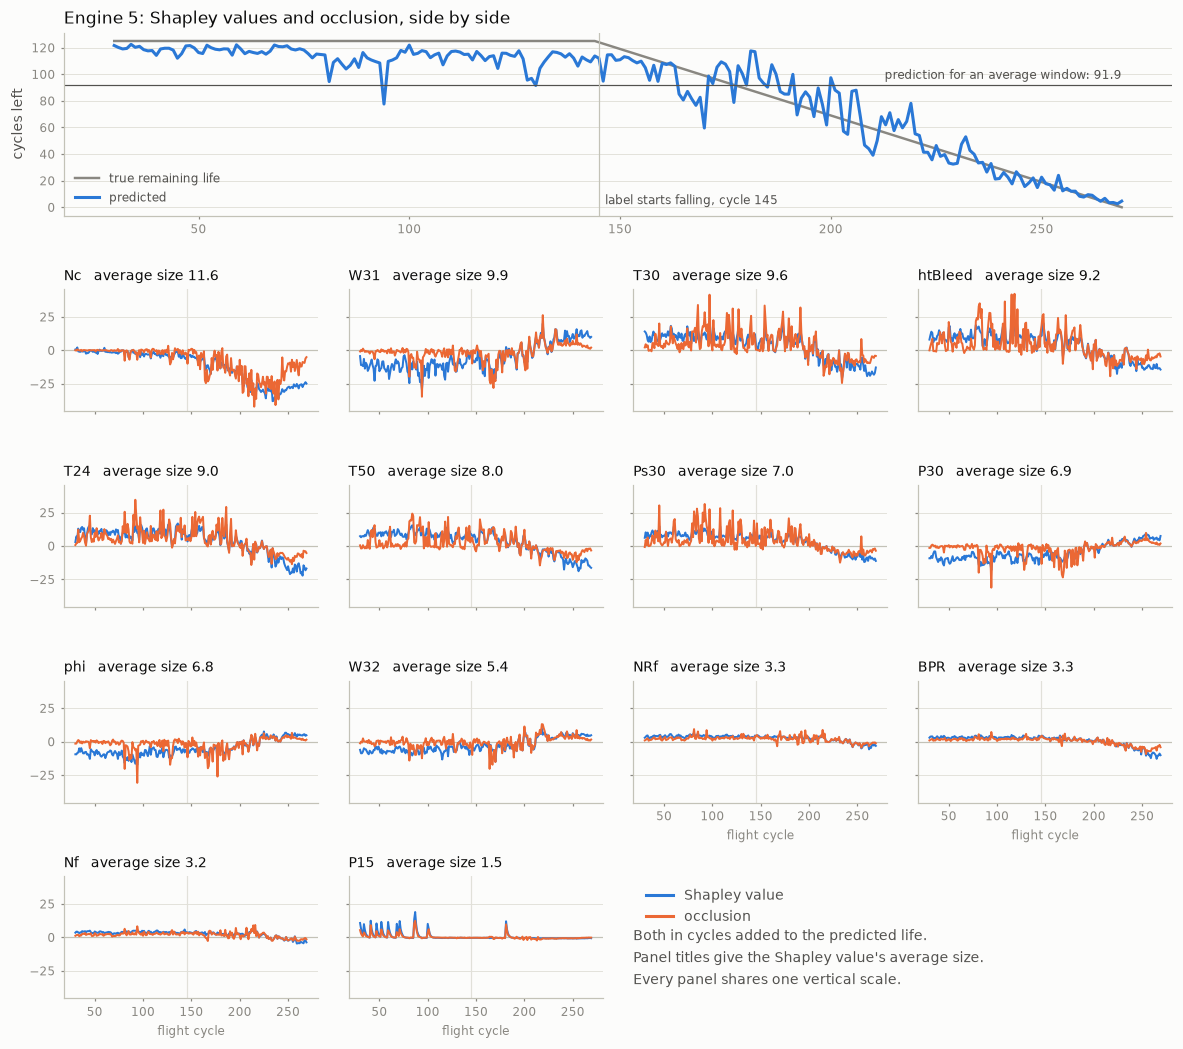

In [9]:
figure = plot_contributions_over_time(
    attribution, sensors, compare=occluded, method="Shapley value",
    compare_method="occlusion",
    title=f"Engine {engine}: Shapley values and occlusion, side by side",
)
plt.show()

#### Reading the figure

**The broad story is the same.** In both lines `Nc` grows into the largest contribution as the engine wears, and `T30`, `htBleed` and `T24` push the prediction up while the engine is healthy.

**But the orange line is closer to zero almost everywhere, and in four panels it nearly vanishes.** While the engine is healthy, `W31`, `P30`, `phi` and `W32` pull the prediction down by several cycles each by Shapley value, and by very little by occlusion. Those four sensors move the prediction a great deal when only some of the other sensors are present, and hardly at all when every other sensor is — and occlusion looks only at the second situation. Measurement 5 in step 5 gives the averages. It is also why `W31`, second by Shapley value, drops much further by occlusion in measurement 2.

### Step 5 — Where the two methods agree, and where they cannot

**What.** Five measurements over all the engine's windows:

1. **Adding up.** How far the fourteen occlusion values miss the prediction minus the reference, window by window, and whether the miss grows where the prediction is close to one of its limits, 0 or 125.
2. **The overall ranking.** Both methods' ranking of the sensors by average size, side by side, and Spearman's rank correlation between them (1 for the same order, 0 for no relationship; the Shapley notebook's step 7 works an example).
3. **Window by window.** The same correlation computed separately at each window, across the fourteen sensors: how often the two methods agree about which sensors matter at a given moment.
4. **The window where they disagree most**, printed in full.
5. **Direction as well as size**, in the first and last third of the engine's life.

**Why.** The chart shows where the lines part. These put numbers to it, so a claim that occlusion is "close enough" or "misleading" can be checked.

In [10]:
distance = (attribution["predicted"] - attribution["baseline"]).to_numpy()
miss = np.abs(occluded.sum(axis=1).to_numpy() - distance)
shapley_miss = np.abs(attribution[sensors].sum(axis=1).to_numpy() - distance)
print("1. How far the 14 values miss (prediction minus reference), in cycles, over all windows:")
print(f"   Shapley values  largest {shapley_miss.max():.1e}")
print(f"   occlusion       median {np.median(miss):.2f}   largest {miss.max():.2f}")
thirds = np.array_split(np.arange(n), 3)
print("   occlusion, by third of the engine's life: medians "
      + ", ".join(f"{np.median(miss[rows]):.2f}" for rows in thirds)
      + f"; rank correlation between the miss and how close the prediction is to 0 or "
      f"125: {stats.spearmanr(miss, np.abs(attribution['predicted'] - 62.5)).statistic:.2f}")

shapley_rank = shap_summary(attribution[sensors].to_numpy(), sensors)
occlusion_rank = shap_summary(occluded.to_numpy(), sensors)
ranks = pd.DataFrame({
    "Shapley value": shapley_rank.set_index("sensor")["mean_abs"],
    "occlusion": occlusion_rank.set_index("sensor")["mean_abs"],
})
ranks["rank by Shapley"] = ranks["Shapley value"].rank(ascending=False).astype(int)
ranks["rank by occlusion"] = ranks["occlusion"].rank(ascending=False).astype(int)
overall = stats.spearmanr(ranks["Shapley value"], ranks["occlusion"]).statistic
print(f"\n2. Average size over all windows, in cycles; rank correlation {overall:.2f}")
display(ranks.sort_values("rank by Shapley").round(2))

per_window = np.array([
    stats.spearmanr(attribution[sensors].iloc[k].abs(), occluded.iloc[k].abs()).statistic
    for k in range(n)
])
print("3. Rank correlation between the methods at each window, across the 14 sensors:")
print(f"   median {np.median(per_window):.2f}, lowest {per_window.min():.2f}; "
      f"{(per_window < 0.5).sum()} of {n} windows below 0.5")

worst = int(np.argmin(per_window))
print(f"\n4. The window where they disagree most ends at cycle {attribution['end_cycle'].iloc[worst]} "
      f"(correlation {per_window[worst]:.2f}):")
display(pd.DataFrame({
    "Shapley value": attribution[sensors].iloc[worst],
    "occlusion": occluded.iloc[worst],
}).sort_values("Shapley value", key=np.abs, ascending=False).round(2))

print("5. Average signed value, first and last third of the engine's life, in cycles:")
display(pd.DataFrame({
    "Shapley, first third": attribution[sensors].iloc[thirds[0]].mean(),
    "occlusion, first third": occluded.iloc[thirds[0]].mean(),
    "Shapley, last third": attribution[sensors].iloc[thirds[2]].mean(),
    "occlusion, last third": occluded.iloc[thirds[2]].mean(),
}).sort_values("Shapley, first third").round(2))

1. How far the 14 values miss (prediction minus reference), in cycles, over all windows:
   Shapley values  largest 4.8e-07
   occlusion       median 19.43   largest 108.45
   occlusion, by third of the engine's life: medians 17.95, 20.56, 20.04; rank correlation between the miss and how close the prediction is to 0 or 125: 0.05

2. Average size over all windows, in cycles; rank correlation 0.92


,Shapley value,occlusion,rank by Shapley,rank by occlusion
sensor,,,,
Nc,11.62,8.57,1,1
W31,9.91,4.57,2,7
T30,9.57,8.04,3,2
htBleed,9.20,7.85,4,4
T24,9.02,7.93,5,3
T50,8.01,5.21,6,6
Ps30,6.97,6.22,7,5
P30,6.93,3.37,8,9
phi,6.75,3.43,9,8


3. Rank correlation between the methods at each window, across the 14 sensors:
   median 0.75, lowest 0.01; 70 of 240 windows below 0.5

4. The window where they disagree most ends at cycle 110 (correlation 0.01):


,Shapley value,occlusion
T24,12.97,7.79
W31,-10.25,-1.40
T30,10.23,-0.00
Ps30,7.24,0.27
P30,-6.52,-1.06
htBleed,6.50,-1.02
T50,6.39,-1.21
phi,-4.98,-0.50
W32,-4.15,0.62
NRf,4.04,2.53


5. Average signed value, first and last third of the engine's life, in cycles:


,"Shapley, first third","occlusion, first third","Shapley, last third","occlusion, last third"
W31,-12.73,-2.65,5.77,3.21
phi,-9.54,-2.05,1.60,0.75
P30,-9.48,-2.12,2.64,1.70
W32,-6.83,-1.27,2.88,2.67
Nc,-1.53,-0.62,-26.55,-19.42
P15,2.95,1.58,-0.70,-0.75
BPR,3.18,1.82,-3.47,-2.55
Nf,3.87,2.33,0.35,0.68
NRf,4.09,2.55,0.36,0.68
Ps30,9.00,7.58,-4.02,-2.22


#### What the measurements say

1. **Occlusion values are not a division of the prediction.** Their sum misses the prediction's distance from the reference by a median of 19.43 cycles and by as much as 108.45. The miss is about the same size in every third of the engine's life, and it is unrelated to how close the prediction is to 0 or to 125 (the rank correlation printed beside the medians is 0.05). So it is not a problem of one stage of wear, or of the prediction pressing against a limit of the network's output.
2. **The overall order mostly survives.** Ranked by average size over the whole life, the two methods correlate at 0.92, agree on `Nc` first and `P15` last, and differ most on `W31`: second by Shapley value, seventh by occlusion.
3. **At a single moment they often disagree.** The median window correlates at 0.75, but 70 of the 240 windows fall below 0.5. At the worst, the window ending at cycle 110, occlusion gives `T30` nothing where its Shapley value is +10.23 cycles, and gives `htBleed` and `T50` the wrong sign.
4. **What it misses has a pattern.** In the first third of the engine's life the four sensors pulling the prediction down — `W31`, `P30`, `phi` and `W32` — average between −6.83 and −12.73 cycles by Shapley value and between −1.27 and −2.65 by occlusion. Of the five sensors pushing up most, four stay within 3.3 cycles between the two methods; the exception is `T50`, at 9.52 against 4.33. The sensors occlusion loses are the ones whose effect depends most on which other sensors are present — which is, by the definition in section 1, exactly the gap between the average over every arrival position and the last position alone.

**For this network, then,** occlusion gives a fair first view of which sensors matter over a whole engine's life, at 3,600 runs of the network instead of 3,932,160. It cannot be read as shares of any one prediction, and it can hide a sensor whose effect depends on the others. Both of those follow from section 1's arithmetic and would hold for any network; the sizes above are facts about this one.

## 5. What occlusion does and does not show

1. **What object is explained?** One prediction, one window at a time, as with Shapley values.
2. **What does the method have access to?** Only inputs and outputs. It never reads the network's parameters.
3. **What does it change?** One sensor's whole window at a time, with every other sensor left at its real readings.
4. **What does it measure?** How far the prediction moves when that one sensor is replaced, in the single situation where every other sensor is present.
5. **What is the result?** Fourteen signed numbers per window, in cycles. Unlike Shapley values, they need not add up to anything.
6. **What does it assume?** The same stand-in as the Shapley values (assumption A-20), and in addition that a sensor's effect measured with every other sensor present is its effect. Section 1 showed that holds only when the sensor does not interact with the others.
7. **What does it not show?**
   - **Shared information.** When two sensors carry the same information, replacing either one alone changes little, so both can look unimportant — the `max(a, b)` example of section 1.
   - **A division of the prediction.** Its values do not add up to the prediction's distance from the reference, so they cannot be read as shares of it. Step 5 measures by how much they miss here.
   - **Cause, which connections carried the information, or anything about another network** — for the same reasons the Shapley notebook's section 6 gives.

**Do not confuse** a small occlusion value with an unimportant sensor. It means only that, with every other sensor present, replacing this one moved the prediction little.

## 6. Final verification

In [11]:
checks = [
    ("The loaded network scores what the run recorded", same_network, f"seed {SEED}"),
    ("Occlusion by hand equals occlusion_values", hand_matches_function, "15 predictions"),
    ("Equation 15 weights the last position 1/14", last_term_weight_is_one_fourteenth,
     f"{weight_of_last:.6f}"),
    ("Shapley values add up on the worked window", shapley_adds_up, f"engine {engine}"),
    ("Shapley values add up at every window", bool(shapley_miss.max() < 1e-4),
     f"{shapley_miss.max():.1e} cycles over {n} windows"),
]
width = max(len(name) for name, _, _ in checks) + 2
print(f"{'CHECK':<{width}} RESULT   DETAIL")
print("-" * (width + 40))
for name, passed, detail in checks:
    print(f"{name:<{width}} {'PASS' if passed else 'FAIL':<8} {detail}")
print("-" * (width + 40))
failed = [name for name, passed, _ in checks if not passed]
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"All {len(checks)} checks passed.")
print(f"\nMeasured, not checked: occlusion misses adding up by up to {miss.max():.2f} cycles, "
      f"and agrees with the Shapley ranking at {overall:.2f} overall.")

CHECK                                             RESULT   DETAIL
-----------------------------------------------------------------------------------------
The loaded network scores what the run recorded   PASS     seed 42
Occlusion by hand equals occlusion_values         PASS     15 predictions
Equation 15 weights the last position 1/14        PASS     0.071429
Shapley values add up on the worked window        PASS     engine 5
Shapley values add up at every window             PASS     4.8e-07 cycles over 240 windows
-----------------------------------------------------------------------------------------
All 5 checks passed.

Measured, not checked: occlusion misses adding up by up to 108.45 cycles, and agrees with the Shapley ranking at 0.92 overall.


## 7. Summary

### What this notebook produced

- **Occlusion values** for one window, worked by hand from fifteen predictions, and for every window of the engine the Shapley notebook follows.
- **The place occlusion holds inside Equation 15**: the single term in which a sensor arrives after all the others, which the Shapley sum weights by 1/14.
- **A side-by-side chart and four measurements** of how far occlusion and the Shapley values agree on this network and this engine.

### Decisions that were not read from the paper

| Decision | Value used | Written up as |
|---|---|---|
| Using occlusion at all | Not in the paper; included as the cheapest method, for comparison | this notebook |
| What stands in for a replaced sensor | Its average window over the training engines, as for the Shapley values | A-20 |
| Which engine is followed over its life | The held-back engine with the most windows, as in the Shapley notebook | this notebook |

### References

- Zeiler, M. D., & Fergus, R. (2014). Visualizing and understanding convolutional networks. *ECCV 2014*, 818-833. The paper that popularised occlusion, for images.
- Shapley, L. S. (1953). A value for n-person games. *Contributions to the Theory of Games II*, 307-317.